# Thử nghiệm mở rộng FD001–FD004 và nghiên cứu cải thiện RUL

Học viên: Phan Nguyễn Mai Phương — MSHV 25002711

Mô hình chính của đề tài chỉ học trên FD001. Notebook này xem lại hai câu hỏi phụ: mô hình
đó có dùng được cho ba subset còn lại của C-MAPSS không, và có cấu hình nào tốt hơn baseline
không. Mọi con số ở đây đọc từ các thí nghiệm đã chạy trong `outputs/`, notebook không huấn
luyện lại mô hình.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cmapss.followup_results import load_followup_results
from cmapss.project import IMPROVEMENT_RUN

%matplotlib inline
ROOT = Path.cwd() if (Path.cwd() / "outputs").is_dir() else Path.cwd().parent
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

## 1. Chạy pipeline trên FD001–FD004

Có hai kiểu đánh giá. Kiểu nội bộ (`within_subset`) huấn luyện và kiểm tra trên cùng một
subset. Kiểu `transfer` lấy mô hình học trên toàn bộ train FD001 để dự đoán test của FD002,
FD003, FD004 mà không học lại. Ở thí nghiệm này window chỉ dài 10 cycle, vì động cơ test
ngắn nhất của FD004 chỉ có 19 cycle. Do đó MAE của FD001 trong bảng dưới (21,9 cycle) không
so trực tiếp được với kết quả chính dùng window 30.

In [2]:
matrix = json.loads((ROOT / "outputs/cross_dataset/matrix.json").read_text(encoding="utf-8"))
rows = []
for item in matrix["evaluations"]:
    metrics, ci = item["metrics"], item["bootstrap"]["intervals"]["mean_engine_mae"]
    rows.append({"source": item["source_dataset"], "target": item["target_dataset"],
                 "type": item["evaluation_type"], "engines": metrics["n_engines"],
                 "mean_engine_mae": metrics["mean_engine_mae"], "ci_lower": ci["ci_lower"],
                 "ci_upper": ci["ci_upper"], "rmse": metrics["rmse"]})
cross = pd.DataFrame(rows)
cross

,source,target,type,engines,mean_engine_mae,ci_lower,ci_upper,rmse
0,FD001,FD001,within_subset,100,21.9258,18.1054,26.0412,29.5936
1,FD002,FD002,within_subset,259,22.3556,19.7104,25.0450,31.3077
2,FD003,FD003,within_subset,100,28.3255,22.4736,34.5537,41.7606
3,FD004,FD004,within_subset,248,27.2218,24.1806,30.3734,36.9311
4,FD001,FD002,transfer,259,60.3215,56.0478,64.7966,70.4603
5,FD001,FD003,transfer,100,47.3949,40.6269,54.3524,59.2140
6,FD001,FD004,transfer,248,58.5731,53.9262,63.3042,69.8148


**Nhận xét.** Khi học và kiểm tra trên cùng subset, FD001 và FD002 có MAE gần nhau (21,9
và 22,4 cycle), còn FD003 và FD004 cao hơn (28,3 và 27,2). Hai subset sau có hai dạng lỗi
thay vì một, nên khó hơn là hợp lý. Ba dòng transfer thì khác hẳn: MAE lên tới 47–60 cycle.

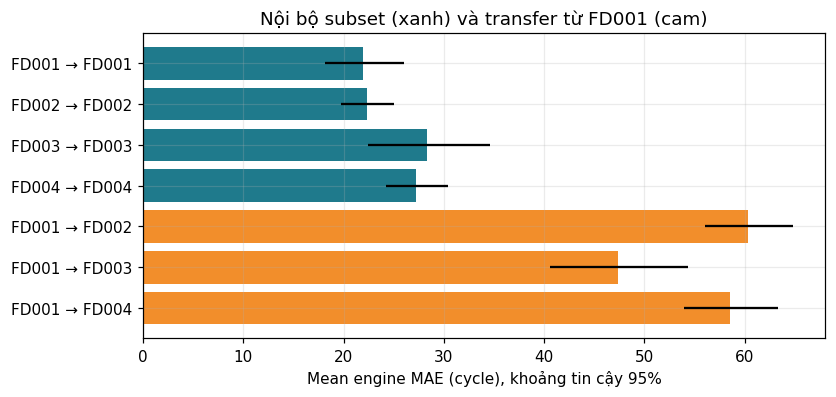

,mean_engine_mae,within_mae,ratio
target,,,
FD002,60.3215,22.3556,2.6983
FD003,47.3949,28.3255,1.6732
FD004,58.5731,27.2218,2.1517


In [3]:
within = cross[cross["type"] == "within_subset"].set_index("target")["mean_engine_mae"]
transfer = cross[cross["type"] == "transfer"].set_index("target")
transfer = transfer.assign(within_mae=within[transfer.index])
transfer["ratio"] = transfer["mean_engine_mae"] / transfer["within_mae"]

fig, ax = plt.subplots(figsize=(8, 3.6))
colors = np.where(cross["type"] == "transfer", "#f28e2b", "#1f7a8c")
ax.barh(cross["source"] + " → " + cross["target"], cross["mean_engine_mae"], color=colors,
        xerr=[cross["mean_engine_mae"] - cross["ci_lower"], cross["ci_upper"] - cross["mean_engine_mae"]])
ax.invert_yaxis()
ax.set(xlabel="Mean engine MAE (cycle), khoảng tin cậy 95%", title="Nội bộ subset (xanh) và transfer từ FD001 (cam)")
plt.show()
transfer[["mean_engine_mae", "within_mae", "ratio"]]

**Nhận xét.** Đem mô hình FD001 sang subset khác làm MAE tăng 1,7 lần ở FD003 và 2,7 lần ở
FD002. Ở cả ba subset, khoảng tin cậy của transfer không chạm vào khoảng tin cậy của đánh giá
nội bộ, nên đây không phải chênh lệch ngẫu nhiên. Nặng nhất là FD002 và FD004, hai subset có
sáu điều kiện vận hành trong khi FD001 chỉ có một. FD003 cùng một điều kiện vận hành với FD001
nên đỡ hơn, dù có thêm dạng lỗi thứ hai. Tóm lại, không nên dùng thẳng mô hình FD001 cho
subset khác; cần học lại, hoặc ít nhất chuẩn hóa sensor theo điều kiện vận hành.

## 2. Nghiên cứu cải thiện RUL bằng nested cross-validation

Nested cross-validation (kiểm định chéo lồng nhau) có hai vòng. Vòng ngoài giữ riêng một nhóm
động cơ để chấm điểm. Vòng trong chỉ dùng các động cơ còn lại để chọn lần lượt độ dài window,
tham số HistGradientBoosting (HGB) và trọng số mẫu. Nhờ vậy điểm ở vòng ngoài không bị lẫn
với bước chọn cấu hình. Mọi phương án được chấm trên cùng tập cycle từ 30 trở đi.

Tôi chốt tiêu chí trước khi chạy: chỉ thay baseline khi cả MAE toàn bộ lẫn MAE ở vùng
RUL ≤ 30 cùng giảm, với khoảng tin cậy nằm hẳn dưới 0.

In [4]:
RUN = ROOT / IMPROVEMENT_RUN
ablation = pd.read_csv(RUN / "ablation_metrics.csv").set_index("stage")
ablation[["mean_engine_mae", "low_rul_engine_mae", "late_or_missed_count", "early_alarm_burden"]]

,mean_engine_mae,low_rul_engine_mae,late_or_missed_count,early_alarm_burden
stage,,,,
baseline,20.2143,3.6676,49,0.0129
windows,20.2143,3.6676,49,0.0129
parameters,20.2459,3.6730,53,0.0126
weights,20.2459,3.6730,53,0.0126


**Nhận xét.** Bước chọn window vẫn giữ window 30, nên dòng `windows` y hệt baseline. Ở bước
chọn tham số HGB, MAE nhích từ 20,21 lên 20,25 cycle và số động cơ bị cảnh báo trễ hoặc bỏ lỡ
tăng từ 49 lên 53. Bước trọng số mẫu không đổi thêm gì. Nhìn bảng này đã thấy quy trình chọn
không đem lại cải thiện; biểu đồ dưới kiểm tra xem chênh lệch có đáng kể không.

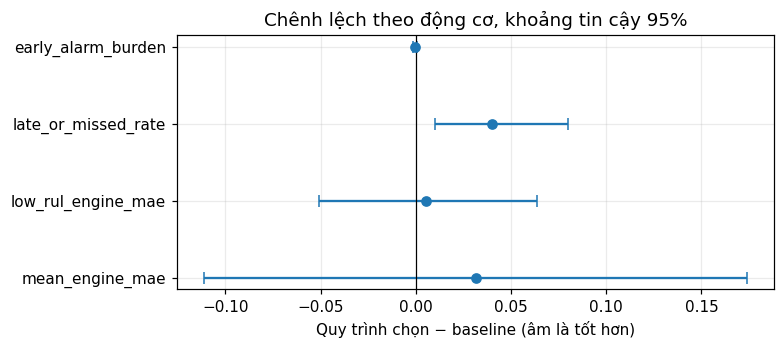

,baseline,candidate,delta,ci_lower,ci_upper
metric,,,,,
mean_engine_mae,20.2143,20.2459,0.0315,-0.1112,0.1737
low_rul_engine_mae,3.6676,3.6730,0.0054,-0.0506,0.0639
late_or_missed_rate,0.4900,0.5300,0.0400,0.0100,0.0800
early_alarm_burden,0.0129,0.0126,-0.0004,-0.0013,0.0006


In [5]:
paired = pd.read_csv(RUN / "paired_comparison.csv")
final = paired[paired["stage"] == "weights"].set_index("metric")

fig, ax = plt.subplots(figsize=(7, 3))
ax.errorbar(final["delta"], final.index, xerr=[final["delta"] - final["ci_lower"], final["ci_upper"] - final["delta"]],
            fmt="o", capsize=4)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="Quy trình chọn − baseline (âm là tốt hơn)", title="Chênh lệch theo động cơ, khoảng tin cậy 95%")
plt.show()
final[["baseline", "candidate", "delta", "ci_lower", "ci_upper"]]

In [6]:
decision = json.loads((RUN / "decision.json").read_text(encoding="utf-8"))
print(json.dumps(decision, indent=2, ensure_ascii=False))

{
  "observed_improvement_meets_plan": false,
  "both_primary_intervals_below_zero": false,
  "default_model": "retain_baseline",
  "interval_scope": "paired engine resampling conditional on stored outer predictions; excludes retraining variability"
}


**Nhận xét.** Cải thiện không đạt. MAE toàn bộ tăng 0,03 cycle và MAE vùng RUL ≤ 30 tăng
0,005 cycle; cả hai khoảng tin cậy đều chứa 0, tức là coi như không đổi. Tỷ lệ cảnh báo trễ
hoặc bỏ lỡ tăng từ 0,49 lên 0,53 và khoảng tin cậy (0,01 đến 0,08) nằm hẳn trên 0, nghĩa là
quy trình chọn còn làm cảnh báo kém đi. Vì vậy `decision.json` ghi
`observed_improvement_meets_plan = false` và tôi giữ baseline làm mô hình mặc định.

Khoảng tin cậy ở đây là bootstrap theo động cơ trên dự đoán đã lưu; nó chưa tính phần dao
động do huấn luyện lại mô hình.

In [7]:
run_info = json.loads((RUN / "run_info.json").read_text(encoding="utf-8"))
print(json.dumps(run_info["selected_final"], indent=2))
pd.read_csv(RUN / "test_comparison.csv")[["model", "mean_engine_mae", "rmse", "nasa_score", "low_rul_engine_mae"]]

{
  "window": 30,
  "weight_scheme": "uniform",
  "learning_rate": 0.05,
  "max_iter": 200,
  "max_leaf_nodes": 31,
  "min_samples_leaf": 20,
  "l2_regularization": 0.0
}


,model,mean_engine_mae,rmse,nasa_score,low_rul_engine_mae
0,baseline,15.349,20.5413,1513.2577,4.383
1,selected_final,15.349,20.5413,1513.2577,4.383


**Nhận xét.** Khi chạy quy trình chọn trên toàn bộ train, cấu hình cuối là window 30, trọng
số đều, learning rate 0,05 và 200 vòng lặp. Trên tập test nó cho kết quả giống hệt baseline:
MAE 15,35 cycle, RMSE 20,54. Nói cách khác, quy trình chọn quay về đúng điểm xuất phát.

## 3. Thí nghiệm bổ sung (29/09/2026)

Sau kết quả trên, tôi thử thêm hai hướng. Với FD001: giới hạn RUL ở 110, 125 hoặc 140
(capped RUL) và thêm 42 đặc trưng lịch sử. Với FD002 và FD004: thêm operational settings và
chuẩn hóa sensor theo từng điều kiện trong sáu điều kiện vận hành; bộ chuẩn hóa chỉ học từ
fold huấn luyện. Cấu hình được chọn bằng 3 fold trong và chấm bằng 5 fold ngoài, chia theo
động cơ.

Tập test đã được xem ở nghiên cứu trước, nên phần này chỉ mang tính khám phá. MAE test thấp
hơn không đủ để thay baseline nếu tiêu chí ở vòng ngoài không đạt.

In [8]:
followup, paired_followup = load_followup_results(ROOT)
outer_cols = ["dataset", "selected_final", "n_features", "baseline_outer_mae", "selected_outer_mae",
              "baseline_outer_nasa", "selected_outer_nasa", "baseline_low_mae", "selected_low_mae",
              "baseline_late", "selected_late", "outer_gate_passed"]
followup[outer_cols]

,dataset,selected_final,n_features,baseline_outer_mae,selected_outer_mae,baseline_outer_nasa,selected_outer_nasa,baseline_low_mae,selected_low_mae,baseline_late,selected_late,outer_gate_passed
0,FD001,cap_none_history_1,168,20.2143,20.2966,1.8850e+08,2.5897e+08,3.6676,3.2171,49,55,False
1,FD002,condition_normalized,132,29.2861,28.0390,6.8599e+08,4.5733e+08,8.7127,6.4849,147,153,True
2,FD004,condition_normalized,132,36.7428,35.4491,6.2056e+12,1.3464e+13,9.1172,7.1714,139,140,True


In [9]:
followup[["dataset", "test_mae", "historical_test_mae", "test_nasa_score", "historical_test_nasa_score",
          "test_rmse", "baseline_outer_rmse", "selected_outer_rmse"]]

,dataset,test_mae,historical_test_mae,test_nasa_score,historical_test_nasa_score,test_rmse,baseline_outer_rmse,selected_outer_rmse
0,FD001,13.0460,15.3490,2.6053e+03,1513.2577,19.3133,33.6359,36.8104
1,FD002,19.1797,22.3556,1.7501e+04,34004.9782,27.4954,42.5488,41.3193
2,FD004,26.6123,27.2218,1.2056e+06,492703.0709,36.7452,56.5950,55.6516


In [10]:
paired_followup[["dataset", "metric", "delta", "ci_lower", "ci_upper"]]

,dataset,metric,delta,ci_lower,ci_upper
0,FD001,mean_engine_mae,0.0823,-1.0680,1.1563
1,FD001,low_rul_engine_mae,-0.4505,-0.6940,-0.2257
2,FD001,late_or_missed_rate,0.0600,-0.0200,0.1400
3,FD001,early_alarm_burden,-0.0029,-0.0052,-0.0008
4,FD002,mean_engine_mae,-1.2471,-1.6650,-0.8141
5,FD002,low_rul_engine_mae,-2.2278,-2.6497,-1.8292
6,FD002,late_or_missed_rate,0.0231,-0.0269,0.0731
7,FD002,early_alarm_burden,-0.0032,-0.0053,-0.0011
8,FD004,mean_engine_mae,-1.2937,-1.8868,-0.6836
9,FD004,low_rul_engine_mae,-1.9458,-2.3837,-1.4745


**Nhận xét.** Với FD001, cấu hình được chọn là `cap_none_history_1` (không cap RUL, thêm đặc
trưng lịch sử). MAE vòng ngoài gần như không đổi (20,21 lên 20,30, khoảng tin cậy của chênh
lệch từ −1,07 đến 1,16), nên không đạt tiêu chí dù MAE vùng RUL thấp giảm 0,45 cycle. MAE test
13,05 thấp hơn 15,35 của baseline, nhưng vì test đã được nhìn trước nên tôi không dùng con số
này để đổi mô hình.

Với FD002 và FD004, chuẩn hóa theo điều kiện vận hành đạt tiêu chí ở vòng ngoài: MAE giảm 1,25
và 1,29 cycle, MAE vùng RUL thấp giảm khoảng 2 cycle, các khoảng tin cậy đều dưới 0. Trên test,
MAE của FD002 giảm từ 22,36 xuống 19,18 và của FD004 từ 27,22 xuống 26,61 (so với kết quả nội
bộ ở phần 1). Tuy vậy, NASA score (phạt nặng các dự đoán trễ) xấu đi ở FD001 và FD004, cả ở
vòng ngoài lẫn trên test, và tỷ lệ cảnh báo trễ không giảm ở subset nào. Cải thiện MAE vì thế
chưa đi kèm cải thiện ở những lần dự đoán quá lạc quan.

## Tóm tắt

Mô hình học trên FD001 không chuyển được sang FD002–FD004: MAE tăng 1,7–2,7 lần. Nested
cross-validation trên FD001 không tìm được cấu hình nào tốt hơn baseline theo tiêu chí đã chốt,
nên baseline được giữ; đây là kết quả âm và tôi giữ nguyên nó trong báo cáo. Thí nghiệm bổ sung
cho thấy chuẩn hóa theo điều kiện vận hành giúp giảm MAE ở FD002 và FD004, nhưng NASA score của
FD004 lại xấu đi, nên cần thử thêm trước khi kết luận đây là cải thiện thật.